TRUE DISTRIBUTION: [0.7 0.2 0.1]
PREDICTED DISTRIBUTION: [0.6 0.3 0.1]

ENTROPY
Entropy H(P): 1.1567796494470395

CROSS ENTROPY
Cross Entropy: 1.1954618442383218

KL DIVERGENCE
KL Divergence: 0.03868219479128224
KL Divergence for Q2: 0.9159631358073556

VERIFICATION
Entropy + KL Divergence: 1.1954618442383218
Cross Entropy: 1.1954618442383218


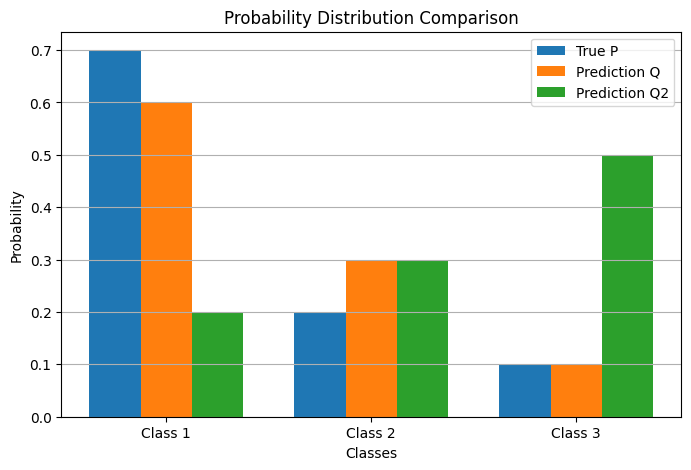

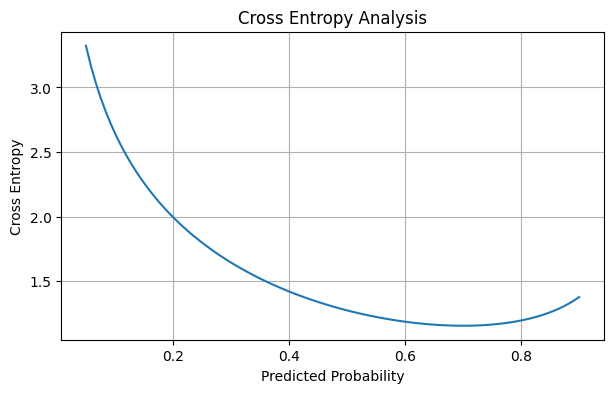

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# 1. Define probability distributions
P = np.array([0.7, 0.2, 0.1])

Q = np.array([0.6, 0.3, 0.1])

Q2 = np.array([0.2, 0.3, 0.5])

print("TRUE DISTRIBUTION:", P)
print("PREDICTED DISTRIBUTION:", Q)

# 2. Calculate entropy
# H(P) = -sum(P * log2(P))

H = entropy(P, base=2)

print("\nENTROPY")
print("Entropy H(P):", H)

# 3. Calculate cross entropy
# H(P,Q) = -sum(P * log2(Q))

cross_entropy = -np.sum(P * np.log2(Q))

print("\nCROSS ENTROPY")
print("Cross Entropy:", cross_entropy)

# 4. Calculate KL Divergence
# DKL(P||Q) = sum(P * log2(P/Q))

kl_divergence = entropy(P, Q, base=2)

print("\nKL DIVERGENCE")
print("KL Divergence:", kl_divergence)

# Compare with another prediction
kl_divergence_2 = entropy(P, Q2, base=2)

print("KL Divergence for Q2:", kl_divergence_2)

# 5. Verify the relationship
print("\nVERIFICATION")

print(
    "Entropy + KL Divergence:",
    H + kl_divergence
)

print(
    "Cross Entropy:",
    cross_entropy
)

# 6. Plot probability distributions
labels = ["Class 1", "Class 2", "Class 3"]

x = np.arange(len(labels))
width = 0.25

plt.figure(figsize=(8, 5))

plt.bar(x - width, P, width, label="True P")
plt.bar(x, Q, width, label="Prediction Q")
plt.bar(x + width, Q2, width, label="Prediction Q2")

plt.xlabel("Classes")
plt.ylabel("Probability")
plt.title("Probability Distribution Comparison")

plt.xticks(x, labels)
plt.legend()
plt.grid(axis="y")

plt.show()

# 7. Cross entropy visualization
values = []

for q1 in np.linspace(0.05, 0.9, 100):

    remaining = 1 - q1

    prediction = np.array([
        q1,
        remaining * 2 / 3,
        remaining / 3
    ])

    ce = -np.sum(
        P * np.log2(prediction)
    )

    values.append(ce)

plt.figure(figsize=(7, 4))

plt.plot(
    np.linspace(0.05, 0.9, 100),
    values
)

plt.xlabel("Predicted Probability")
plt.ylabel("Cross Entropy")
plt.title("Cross Entropy Analysis")
plt.grid()

plt.show()